# Passo 5: treino e avaliação do modelo

Objetivo: prever, para cada recorte e mês, se a inadimplência vai ter **alta relevante em 6 meses** (alvo = 1).

**Métricas** (a acurácia engana quando só 13% a 25% dos casos são positivos):
- **AUC:** 0,5 = chute, 1,0 = perfeito. Mede se o modelo dá nota maior aos recortes que de fato subiram.
- **AP (precisão média):** comparar com a proporção de positivos, que é o valor de um chute.

**Roteiro:**
1. Validação temporal **dentro do treino** para escolher o modelo, sem olhar o teste.
2. Modelo escolhido: **floresta aleatória** (desempenho próximo ao do gradient boosting na validação, com bem menos sobreajuste).
3. Avaliação **uma única vez** no teste de 2025.

In [1]:
import pandas as pd

from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, roc_auc_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

from src.dados import PASTA_PROCESSED

VARIAVEIS_NUM = [
    "taxa_inad",
    "taxa_atraso_15_90",
    "taxa_problematico",
    "var_taxa_inad_3m",
    "var_taxa_inad_6m",
    "var_atraso_15_90_3m",
    "cresc_carteira_3m",
    "cresc_carteira_6m",
]
VARIAVEIS_CAT = ["uf", "cliente", "modalidade"]
VARIAVEIS = VARIAVEIS_NUM + VARIAVEIS_CAT

# Base do passo 4, já com a coluna "parte" (treino / intervalo / teste)
base = pd.read_parquet(PASTA_PROCESSED / "base_modelo.parquet")
treino = base[base["parte"] == "treino"]
teste = base[base["parte"] == "teste"]

print(f"Treino: {len(treino)} linhas, {100 * treino['alvo'].mean():.1f}% positivos")
print(f"Teste:  {len(teste)} linhas, {100 * teste['alvo'].mean():.1f}% positivos")

Treino: 9264 linhas, 13.0% positivos
Teste:  2316 linhas, 24.9% positivos


In [2]:
def criar_preparador(padronizar):
    """Prepara as colunas antes do modelo.

    - Numéricas: padroniza (média 0, desvio 1) só para a regressão logística,
      que é sensível à escala; as árvores não precisam ("passthrough").
    - Categóricas: OneHotEncoder cria uma coluna 0/1 para cada categoria.
      handle_unknown="ignore" evita erro se aparecer uma categoria nova.
    """
    return ColumnTransformer([
        ("num", StandardScaler() if padronizar else "passthrough", VARIAVEIS_NUM),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), VARIAVEIS_CAT),
    ])


def criar_modelos():
    """Cada Pipeline junta a preparação e o modelo num objeto só:
    fit() aprende os dois no treino, predict_proba() aplica os dois.
    class_weight="balanced" dá mais peso aos positivos, que são minoria.
    random_state fixa o sorteio interno para o resultado ser reproduzível."""
    return {
        "Regressão logística": Pipeline([
            ("prep", criar_preparador(padronizar=True)),
            ("modelo", LogisticRegression(max_iter=2000, class_weight="balanced")),
        ]),
        "Floresta aleatória": Pipeline([
            ("prep", criar_preparador(padronizar=False)),
            ("modelo", RandomForestClassifier(
                n_estimators=300,      # número de árvores
                min_samples_leaf=20,   # cada folha precisa de 20+ linhas: reduz sobreajuste
                class_weight="balanced",
                n_jobs=-1,             # usa todos os núcleos do processador
                random_state=42,
            )),
        ]),
        "Gradient boosting": Pipeline([
            ("prep", criar_preparador(padronizar=False)),
            ("modelo", HistGradientBoostingClassifier(class_weight="balanced", random_state=42)),
        ]),
    }


def avaliar(dados_treino, dados_avaliacao):
    """Treina cada modelo e devolve uma tabela com AUC e AP."""
    X_tr, y_tr = dados_treino[VARIAVEIS], dados_treino["alvo"]
    X_av, y_av = dados_avaliacao[VARIAVEIS], dados_avaliacao["alvo"]

    # Referência sem modelo: ordenar os recortes pela taxa de atraso de 15 a 90 dias
    linhas = [{
        "modelo": "Regra simples (atraso 15-90)",
        "AUC": roc_auc_score(y_av, dados_avaliacao["taxa_atraso_15_90"]),
        "AP": average_precision_score(y_av, dados_avaliacao["taxa_atraso_15_90"]),
        "AUC no treino": None,
    }]
    modelos = criar_modelos()
    for nome, modelo in modelos.items():
        modelo.fit(X_tr, y_tr)
        # predict_proba devolve [P(alvo=0), P(alvo=1)]; ficamos com a 2ª coluna
        prob = modelo.predict_proba(X_av)[:, 1]
        prob_tr = modelo.predict_proba(X_tr)[:, 1]
        linhas.append({
            "modelo": nome,
            "AUC": roc_auc_score(y_av, prob),
            "AP": average_precision_score(y_av, prob),
            "AUC no treino": roc_auc_score(y_tr, prob_tr),
        })
    tabela = pd.DataFrame(linhas).set_index("modelo").round(3)
    print(f"AP de um chute (proporção de positivos): {y_av.mean():.3f}")
    return tabela, modelos

In [3]:
# Validação temporal DENTRO do treino (o teste fica guardado):
# sub-treino jul/2022 a jun/2023, intervalo de 6 meses, validação jan a jun/2024
sub_treino = treino[treino["data_base"] <= "2023-06-30"]
validacao = treino[treino["data_base"] >= "2024-01-01"]
print(f"Sub-treino: {len(sub_treino)} linhas | Validação: {len(validacao)} linhas")

tabela_validacao, _ = avaliar(sub_treino, validacao)
tabela_validacao

Sub-treino: 4632 linhas | Validação: 2316 linhas
AP de um chute (proporção de positivos): 0.127


,AUC,AP,AUC no treino
modelo,,,
Regra simples (atraso 15-90),0.628,0.200,NaN
Regressão logística,0.636,0.209,0.872
Floresta aleatória,0.704,0.219,0.920
Gradient boosting,0.723,0.226,0.998


In [4]:
# Avaliação final: treina no treino completo (jul/2022 a jun/2024)
# e mede UMA vez no teste (jan a jun/2025)
tabela_teste, modelos = avaliar(treino, teste)
floresta = modelos["Floresta aleatória"]
tabela_teste

AP de um chute (proporção de positivos): 0.249


,AUC,AP,AUC no treino
modelo,,,
Regra simples (atraso 15-90),0.690,0.369,NaN
Regressão logística,0.678,0.414,0.827
Floresta aleatória,0.770,0.527,0.917
Gradient boosting,0.712,0.462,0.990


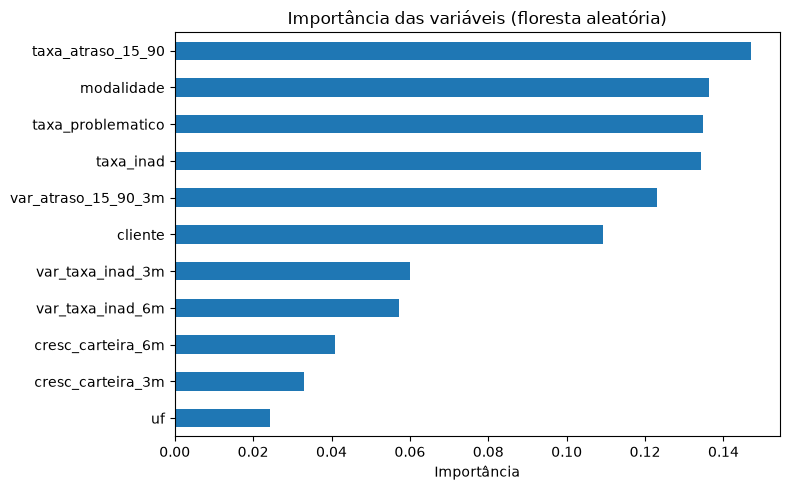

taxa_atraso_15_90      0.147
modalidade             0.136
taxa_problematico      0.135
taxa_inad              0.134
var_atraso_15_90_3m    0.123
cliente                0.109
var_taxa_inad_3m       0.060
var_taxa_inad_6m       0.057
cresc_carteira_6m      0.041
cresc_carteira_3m      0.033
uf                     0.024
dtype: float64


In [5]:
import matplotlib.pyplot as plt

# Importância de cada coluna na floresta (quanto ela ajuda a separar os casos)
nomes = floresta.named_steps["prep"].get_feature_names_out()
importancias = pd.Series(floresta.named_steps["modelo"].feature_importances_, index=nomes)

# O OneHotEncoder dividiu cada categórica em várias colunas (ex.: cat__uf_SP);
# somamos essas colunas para ter a importância da variável original
def variavel_original(nome):
    for cat in VARIAVEIS_CAT:
        if nome.startswith(f"cat__{cat}_"):
            return cat
    return nome.replace("num__", "")

importancia_var = importancias.groupby(variavel_original).sum().sort_values()

importancia_var.plot.barh(figsize=(8, 5), title="Importância das variáveis (floresta aleatória)")
plt.xlabel("Importância")
plt.tight_layout()
plt.show()

print(importancia_var.sort_values(ascending=False).round(3))